In [1]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # hides harmless Mac maths warnings
from sklearn.base import clone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate,GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
confusion_matrix, ConfusionMatrixDisplay, classification_report,
RocCurveDisplay

)

df = pd.read_csv("classification_escalation.csv")
print(df.shape)
display(df.head())
print(df.info())
print(df["escalated"].value_counts(normalize=True).rename("proportion"))


(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    object 
 3   channel                 900 non-null    object 
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 42.3+ KB
None
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


## Data observations
- The dataset has 900 rows and 6 columns.
- Numeric predictors: complexity_score, team_experience_years, customer_tenure_months.
- Categorical predictors: priority, channel.
- Missing values: 31 (team_experience_years), 22 (customer_tenure_months), 18 (priority).
- About 20.7% of tickets escalated, so the classes are imbalanced.

## Problem framing
This is a classification task because the target, escalated, is a category with two values (1 = escalated, 0 = not escalated), not a number on a continuous scale. The goal is to predict which class a ticket belongs to, or the probability that it will escalate.

The positive class is escalated = 1. It is the event we want to catch early, it is the rarer class (about 21% of tickets), and missing it is the more expensive mistake (a missed escalation costs 5, a false alarm costs 1). 

In [2]:
numeric_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
categorical_cols = ["priority", "channel"]

X = df[numeric_cols + categorical_cols]
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print("Train escalation rate:", y_train.mean())
print("Test escalation rate:", y_test.mean())

(675, 5) (225, 5)
Train escalation rate: 0.2074074074074074
Test escalation rate: 0.20444444444444446


In [3]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols),
])

In [4]:
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15),
}

fitted = {}
rows = []

for name, model in models.items():
    pipe = Pipeline([("prep", clone(preprocess)), ("clf", model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Majority baseline,0.796,0.00,0.000,0.000,0.500
Logistic regression,0.822,0.75,0.196,0.310,0.811
LDA,0.822,0.75,0.196,0.310,0.809
k-NN (k=15),0.796,0.50,0.087,0.148,0.705


## Model comparison
- The majority baseline reaches an accuracy of 0.796 but a recall of 0: it never predicts an escalation.
- Logistic regression reaches an accuracy of 0.822, only a little higher than the baseline, with recall 0.196 and precision 0.75.
- LDA gets 0.196 recall and 0.310 F1, very close to logistic regression.
- k-NN (k=15) is the weakest real model, with recall 0.087 and ROC-AUC 0.705.
- The highest ROC-AUC is 0.811 (Logistic regression).
- Recall is low for every model because only about 21% of tickets escalate, so few tickets get a probability above the default 0.5 threshold.


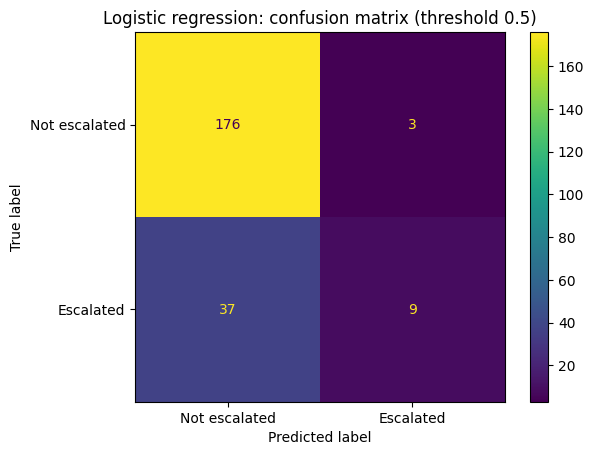

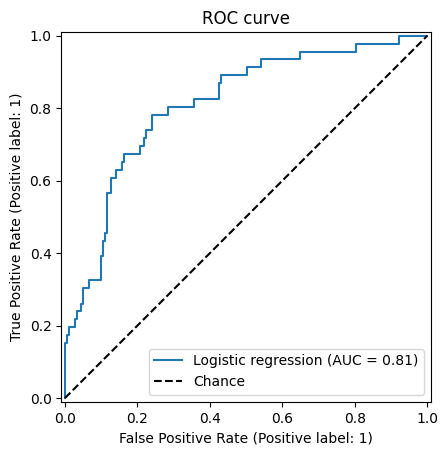

In [5]:
lr = fitted["Logistic regression"]
lr_pred = lr.predict(X_test)
lr_proba = lr.predict_proba(X_test)[:, 1]

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred, display_labels=["Not escalated", "Escalated"]
)
plt.title("Logistic regression: confusion matrix (threshold 0.5)")
plt.show()

RocCurveDisplay.from_predictions(y_test, lr_proba, name="Logistic regression")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.legend()
plt.title("ROC curve")
plt.show()


## Confusion matrix and ROC curve
At the default threshold of 0.5, logistic regression caught only 9 of the 46 tickets that really escalated and missed 37. It raised 3 false alarms. The ROC curve is well above the diagonal (AUC = 0.81), which means the model ranks risky tickets reasonably well. The problem is the 0.5 threshold, which is too strict for this task.

In [6]:
rows = []
for t in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    pred = (lr_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({
        "Threshold": t,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred, zero_division=0),
        "FP": fp,
        "FN": fn,
        "Cost (5*FN + FP)": 5 * fn + fp,
    })

thr = pd.DataFrame(rows).set_index("Threshold").round(3)
display(thr)
print("Lowest-cost threshold:", thr["Cost (5*FN + FP)"].idxmin())

,Precision,Recall,F1,FP,FN,Cost (5*FN + FP)
Threshold,,,,,,
0.2,0.429,0.783,0.554,48,10,98
0.3,0.549,0.609,0.577,23,18,113
0.4,0.571,0.261,0.358,9,34,179
0.5,0.750,0.196,0.310,3,37,188
0.6,1.000,0.065,0.122,0,43,215
0.7,0.000,0.000,0.000,0,46,230


Lowest-cost threshold: 0.2


## Threshold analysis
As the threshold is lowered from 0.70 to 0.20, the model flags more tickets. False negatives fall from 46 to 10 and recall rises from 0 to 0.783, but false positives rise from 0 to 48 and precision falls (from 1.000 at 0.6 to 0.429 at 0.2).

The lowest cost on the test set is at threshold 0.2, with cost 98, compared with 188 at the default threshold of 0.5. The best F1 is at threshold 0.3 (0.577), which is not the same as the lowest-cost threshold. F1 treats a missed escalation and a false alarm as equally bad, but the cost function makes a miss 5 times worse, so it prefers the lower threshold that catches more escalations.

Note: at threshold 0.7 no ticket is flagged at all, so precision is actually undefined; it is shown as 0 only because of `zero_division=0`.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_pipe = Pipeline([("prep", clone(preprocess)), ("clf", KNeighborsClassifier())])

grid = GridSearchCV(
    knn_pipe,
    param_grid={"clf__n_neighbors": [5, 9, 15, 21, 31]},
    scoring="f1",
    cv=cv,
)
grid.fit(X_train, y_train)

print("Best k:", grid.best_params_["clf__n_neighbors"])
print("Best mean CV F1:", round(grid.best_score_, 3))
pd.DataFrame(grid.cv_results_)[["param_clf__n_neighbors", "mean_test_score", "std_test_score"]].round(3)

Best k: 5
Best mean CV F1: 0.243


,param_clf__n_neighbors,mean_test_score,std_test_score
0,5,0.243,0.095
1,9,0.198,0.065
2,15,0.160,0.065
3,21,0.146,0.056
4,31,0.112,0.040


## Tuning k for k-NN
Using stratified 5-fold cross-validation on the training set, the best k is 5 with a mean F1 of 0.243. F1 goes down steadily as k gets larger (0.243 at k=5, 0.198 at k=9, 0.160 at k=15, 0.146 at k=21 and 0.112 at k=31). With many neighbours, each prediction averages over more tickets, so the predicted probability moves toward the overall escalation rate (about 21%) and rarely reaches 0.5, so fewer escalations are caught. The standard deviations (0.040 to 0.095) are large compared with the differences, so the ranking is not very stable. Even the best k-NN is weaker than logistic regression and LDA.

## Answers to the questions

**1. Why is accuracy alone potentially misleading?**
About 79% of the tickets are not escalated, so a model that always predicts "not escalated" already gets 0.796 accuracy without finding any escalations. Logistic regression got 0.822 accuracy but still missed 37 of the 46 escalated tickets. Accuracy also treats both types of mistakes the same, even though missing an escalation costs more here.

**2. Which classifier has the strongest recall? Which has the strongest precision/F1?**
Logistic regression and LDA got the same results at the 0.5 threshold: recall 0.196, precision 0.75 and F1 0.310. k-NN was lower on all three. Logistic regression had a slightly higher ROC-AUC (0.811 vs 0.809).

**3. What changes when the threshold is lowered?**
The model predicts more tickets as escalated. Recall increases and there are fewer false negatives, but precision decreases and there are more false positives. From 0.5 to 0.2, recall went from 0.196 to 0.783 and false positives went from 3 to 48.

**4. Which threshold minimizes 5×FN + FP on the test set, and why might this estimate be optimistic?**
Threshold 0.2 has the lowest cost (98). This can be optimistic because the threshold was chosen using the test set itself. If we keep tuning on the test set, the result partly fits that specific data and will probably look better than it would on new tickets. The threshold should be chosen using cross-validation or a validation set.

**5. Explain prior, likelihood, posterior and evidence.**
- Prior P(escalated): the chance a ticket escalates before looking at its features, about 0.21.
- Likelihood p(x | escalated): how likely we are to see this ticket's features if the ticket is escalated.
- Evidence p(x): how likely these features are overall, across all tickets.
- Posterior P(escalated | x): the probability the ticket escalates after seeing its features. It equals likelihood × prior / evidence.

**6. Expected cost with P(escalated | x) = 0.30**
- Escalate: 1 × (1 - 0.30) = 0.70
- Don't escalate: 5 × 0.30 = 1.50

Escalating has the lower expected cost, so the ticket should be escalated. We escalate when C_FP(1 - p) < C_FN × p, so p > C_FP / (C_FP + C_FN) = 1 / (1 + 5) ≈ 0.167.

**7. Which model would you recommend for deployment, and what further checks are required?**
Logistic regression with a threshold around 0.17 to 0.20. Before deployment it should be tested on real data, checked for calibration, checked across different channels and priorities, and monitored after deployment.

## Recommendation

I recommend logistic regression for this problem. On the test set it had 0.822 accuracy, 0.75 precision, 0.196 recall and a ROC-AUC of 0.811. LDA gave almost the same results, but logistic regression is simpler to explain because each feature has a coefficient that shows if it increases or decreases the chance of escalation. k-NN performed worse, even after tuning k with cross-validation (best k = 5, F1 = 0.243). The majority baseline had 0.796 accuracy but did not find any escalations, which shows that accuracy alone is not a good way to compare the models.

The default threshold of 0.5 is not a good choice here. At 0.5 the model only found 9 of the 46 escalated tickets. Because a missed escalation costs 5 and a false alarm costs 1, the cost-sensitive threshold is 1 / (1 + 5), which is about 0.17. The threshold table showed the same thing: 0.2 had the lowest cost (98) compared to 188 at 0.5. So I would use a threshold between 0.17 and 0.20. Since this was compared on the test set, the threshold should be checked again with cross-validation.

A false negative means a ticket that should be escalated is missed, which can lead to an unhappy customer. A false positive means a ticket gets reviewed when it did not need to be. With a threshold of 0.2 there are more false positives (48 instead of 3), but many more escalations are caught (36 instead of 9). Since missing an escalation costs more, this trade-off makes sense.

There are some limitations. The dataset is synthetic and small, and the test set only has 46 escalated tickets, so the results may change with other data. The model is only moderately good (ROC-AUC 0.81), and at a low threshold many flagged tickets will not actually escalate. The 5:1 cost ratio is also an assumption, and missing values were filled with simple methods.

The model should be used to support agents and not to make final decisions alone. A lower threshold means more tickets to review, so the team needs enough time and staff for that. Since team experience is a feature, the model should not be used to judge employees. Before using it, it should be tested on real data, checked for different channels and priorities, and monitored over time.